C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8293 - loss: 0.6762 - val_accuracy: 0.9148 - val_loss: 0.3242
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9011 - loss: 0.3547 - val_accuracy: 0.9283 - val_loss: 0.2641
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9143 - loss: 0.3037 - val_accuracy: 0.9357 - val_loss: 0.2341
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9229 - loss: 0.2729 - val_accuracy: 0.9418 - val_loss: 0.2127
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9300 - loss: 0.2499 - val_accuracy: 0.9473 - val_loss: 0.1976
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9355 - loss: 0.2306 - val_accuracy: 0.9520 - val_loss: 0.1823
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9401 - loss: 0.2142 - val_accuracy: 0.9547 - val_loss: 0.1701
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9436 - loss: 0.2003 - 

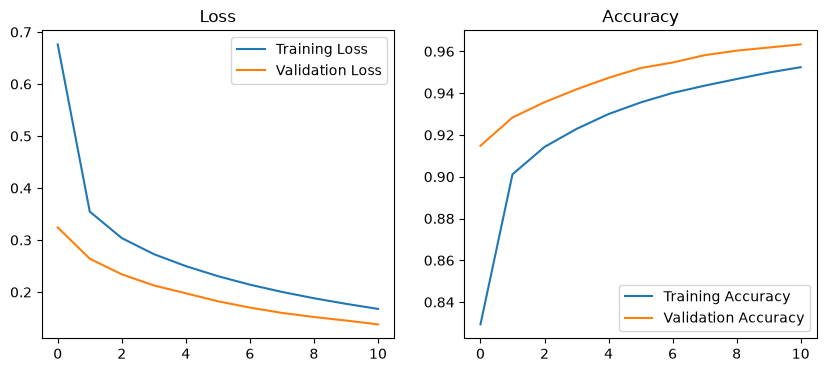

In [3]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

# Load dataset
train_data = pd.read_csv(r"D:\DL\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_train.csv")
test_data = pd.read_csv(r"D:\DL\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_test.csv")

# Split features and labels
x_train = train_data.drop('label', axis=1).values / 255.0
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values / 255.0
y_test = test_data['label'].values

# Create FNN model
model = Sequential([
    Flatten(input_shape=(784,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='SGD',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    x_train, y_train,
    epochs=11,
    validation_split=0.1
)

# Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Plot loss and accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.show()